# Smart Home Energy Consumption Prediction
## Notebook 2: Models, tuning, evaluation and prediction
This notebook completes PDF stages **8–12**. Run Notebook 1 first if regenerating the CSVs. All results below are computed by the code; no external application, saved model or HTML page is needed.

**Workflow:** load model-ready data → chronological split → baselines → two ML approaches → small time-aware tuning search → validation selection → final test → prediction demo.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

SEED = 42
sns.set_theme(style='whitegrid')
DATA = Path('data')
df = pd.read_csv(DATA / 'model_ready_energydata.csv', parse_dates=['date', 'target_time'])
feature_cols = df.columns.drop(['date', 'target_time', 'next_appliances_Wh']).tolist()
X, y = df[feature_cols], df['next_appliances_Wh']
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)
print('Rows:', len(df), '| Predictors:', len(feature_cols))

Python: 3.14.8 | scikit-learn: 1.9.1
Rows: 19729 | Predictors: 11


## Validation strategy and leakage checks
Use the first 70% for training, the next 15% for validation and the last 15% for the final test. Remove **one boundary row** from the end of train and validation so each earlier split's last target time is strictly before the next split's first input time.

Validation MAE selects the model. Cross-validation for tuning stays inside the training period and uses expanding time windows with a one-row gap. Scaling and imputation happen inside each fitted pipeline. The test period is evaluated after selection and does not change the selected model.

Historical meter values within validation/test are permitted because this is a rolling one-step forecast, where the latest real observation arrives before the next prediction. This would not be valid for a multi-step forecast without those observations.

In [2]:
n = len(df)
a, b = int(0.70 * n), int(0.85 * n)
X_train, y_train = X.iloc[:a-1], y.iloc[:a-1]
X_val, y_val = X.iloc[a:b-1], y.iloc[a:b-1]
X_test, y_test = X.iloc[b:], y.iloc[b:]
assert df.iloc[a-2]['target_time'] < df.iloc[a]['date']
assert df.iloc[b-2]['target_time'] < df.iloc[b]['date']
assert set(feature_cols).isdisjoint({'next_appliances_Wh', 'date', 'target_time'})

split_info = []
for name, idx in [('Train', X_train.index), ('Validation', X_val.index), ('Test', X_test.index)]:
    split_info.append({'Split': name, 'Rows': len(idx), 'First input': df.loc[idx[0], 'date'], 'Last target': df.loc[idx[-1], 'target_time']})
display(pd.DataFrame(split_info))
print('Two boundary rows excluded; no random train/test shuffle.')

def scores(actual, prediction):
    mse = mean_squared_error(actual, prediction)
    return {'MAE_Wh': mean_absolute_error(actual, prediction), 'MSE_Wh2': mse,
            'RMSE_Wh': np.sqrt(mse), 'R2': r2_score(actual, prediction)}

,Split,Rows,First input,Last target
0,Train,13809,2016-01-11 17:50:00,2016-04-16 15:20:00
1,Validation,2958,2016-04-16 15:30:00,2016-05-07 04:30:00
2,Test,2960,2016-05-07 04:40:00,2016-05-27 18:00:00


Two boundary rows excluded; no random train/test shuffle.


## 8. Baseline models
**Mean baseline:** always predicts the training mean. It asks whether the model learns anything useful at all.

**Persistence baseline:** predicts that the next reading equals the current reading. It is a stronger reference for short-term forecasting. It fails when consumption changes abruptly.

**Primary metric: MAE**, the average absolute error in Wh, chosen before experiments because it is easy to explain and less dominated by spikes than squared error. **MSE** is squared Wh; **RMSE** is Wh and penalizes large mistakes more. **R²** measures improvement over a constant mean on that evaluation split; it can be negative. These are regression metrics, not classification accuracy.

In [3]:
mean_model = DummyRegressor(strategy='mean').fit(X_train, y_train)
models = {'Training mean': mean_model}
validation_predictions = {
    'Training mean': mean_model.predict(X_val),
    'Persistence': X_val['current_Wh'].to_numpy()
}
display(pd.DataFrame({name: scores(y_val, pred) for name, pred in validation_predictions.items()}).T.round(3))

,MAE_Wh,MSE_Wh2,RMSE_Wh,R2
Training mean,53.990,8541.659,92.421,-0.003
Persistence,26.163,4415.450,66.449,0.481


## 9. Two relevant ML approaches
**Linear Regression** fits an additive weighted sum of the predictors by minimizing squared error. It is simple and explainable, but assumes a linear conditional mean and can miss interactions. Standard scaling helps compare input scales; it is fitted on training data only. Correlated historical features can make individual coefficients unstable, so coefficients should not be interpreted causally. Sequential observations are not independent, so we do not claim classical coefficient significance tests.

**Random Forest** averages many decision trees. It can capture nonlinear relationships and interactions without scaling, but may overfit and cannot extrapolate well beyond observed training values. A small forest and limited depth keep this assignment manageable.

**Deep Learning:** excluded because a modest tabular dataset and two classical models suffice for a meaningful comparison. There is no justified need for neural-network complexity.

In [4]:
linear = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LinearRegression())
forest = make_pipeline(SimpleImputer(strategy='median'),
                       RandomForestRegressor(n_estimators=60, max_depth=10,
                                             min_samples_leaf=5, random_state=SEED, n_jobs=2))
for name, model in [('Linear Regression', linear), ('Random Forest', forest)]:
    model.fit(X_train, y_train)
    models[name] = model
    validation_predictions[name] = model.predict(X_val)
display(pd.DataFrame({name: scores(y_val, pred) for name, pred in validation_predictions.items()}).T.round(3))

,MAE_Wh,MSE_Wh2,RMSE_Wh,R2
Training mean,53.990,8541.659,92.421,-0.003
Persistence,26.163,4415.450,66.449,0.481
Linear Regression,27.047,3629.665,60.247,0.574
Random Forest,28.542,3626.320,60.219,0.574


### Validate the feature-engineering decision
Compare Linear Regression with and without the three historical energy features on the same validation period. This checks whether added history actually helps out-of-time performance. The small sensor set was chosen for clarity; we make no claim that it is the globally optimal feature subset.

In [5]:
history_cols = ['current_Wh', 'lag_10m_Wh', 'mean_1h_Wh']
sensor_cols = [c for c in feature_cols if c not in history_cols]
sensor_linear = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LinearRegression())
sensor_linear.fit(X_train[sensor_cols], y_train)
sensor_mae = mean_absolute_error(y_val, sensor_linear.predict(X_val[sensor_cols]))
history_mae = mean_absolute_error(y_val, validation_predictions['Linear Regression'])
display(pd.DataFrame({'Features': ['Sensors + calendar', 'Sensors + calendar + energy history'],
                      'Validation MAE (Wh)': [sensor_mae, history_mae]}).round(3))
print('Adding history changes validation MAE by', round(history_mae - sensor_mae, 3), 'Wh (negative means improvement).')

,Features,Validation MAE (Wh)
0,Sensors + calendar,46.353
1,Sensors + calendar + energy history,27.047


Adding history changes validation MAE by -19.306 Wh (negative means improvement).


## 10. Hyperparameter tuning
Test only **four** Random Forest configurations: two depths × two leaf sizes, with 60 trees fixed for a practical runtime. Three expanding-window folds use **training data only**. Select the configuration with the lowest mean CV MAE, then compare it with the other candidates on validation.

Tuning can fail to improve performance. The printed default/tuned comparison records what happened rather than assuming success. Linear Regression has no tree-depth or learning-rate hyperparameters to tune.

In [6]:
cv = TimeSeriesSplit(n_splits=3, gap=1)
for train_idx, valid_idx in cv.split(X_train):
    assert df.loc[X_train.index[train_idx[-1]], 'target_time'] < df.loc[X_train.index[valid_idx[0]], 'date']

search = GridSearchCV(
    forest,
    {'randomforestregressor__max_depth': [8, 14],
     'randomforestregressor__min_samples_leaf': [3, 10]},
    scoring='neg_mean_absolute_error', cv=cv, n_jobs=1, return_train_score=True
)
search.fit(X_train, y_train)
models['Tuned Random Forest'] = search.best_estimator_
validation_predictions['Tuned Random Forest'] = search.predict(X_val)
tuning = pd.DataFrame(search.cv_results_)
tuning['CV_MAE_Wh'] = -tuning['mean_test_score']
tuning['Train_MAE_Wh'] = -tuning['mean_train_score']
display(tuning[['param_randomforestregressor__max_depth', 'param_randomforestregressor__min_samples_leaf',
                'Train_MAE_Wh', 'CV_MAE_Wh', 'rank_test_score']].sort_values('rank_test_score').round(3))
print('Best parameters:', search.best_params_)

,param_randomforestregressor__max_depth,param_randomforestregressor__min_samples_leaf,Train_MAE_Wh,CV_MAE_Wh,rank_test_score
1,8,10,27.335,30.347,1
3,14,10,25.849,30.645,2
0,8,3,25.007,30.947,3
2,14,3,19.595,32.400,4


Best parameters: {'randomforestregressor__max_depth': 8, 'randomforestregressor__min_samples_leaf': 10}


## 11. Model selection and final evaluation
Select once by validation MAE, including the honest possibility that persistence wins. Keep the fitted training models fixed for final testing; do not retune or reselect on test results. Report train, validation and test separately to reveal overfitting.

In [7]:
validation_table = pd.DataFrame({name: scores(y_val, pred) for name, pred in validation_predictions.items()}).T
best_name = validation_table['MAE_Wh'].idxmin()
print('Selected using validation MAE:', best_name)

def predict_with(name, inputs):
    if name == 'Persistence':
        return inputs['current_Wh'].to_numpy()
    return models[name].predict(inputs)

rows = []
for name in validation_predictions:
    for split, inputs, actual in [('Train', X_train, y_train), ('Validation', X_val, y_val), ('Test', X_test, y_test)]:
        rows.append({'Model': name, 'Split': split, **scores(actual, predict_with(name, inputs))})
results = pd.DataFrame(rows)
display(results.round(3))
print('No test-set result is used to change the selection above.')

Selected using validation MAE: Persistence


,Model,Split,MAE_Wh,MSE_Wh2,RMSE_Wh,R2
0,Training mean,Train,64.327,11420.977,106.869,0.000
1,Training mean,Validation,53.990,8541.659,92.421,-0.003
2,Training mean,Test,52.843,8263.740,90.905,-0.000
3,Persistence,Train,30.911,5509.805,74.228,0.518
4,Persistence,Validation,26.163,4415.450,66.449,0.481
5,Persistence,Test,26.747,4468.682,66.848,0.459
6,Linear Regression,Train,31.669,4630.736,68.050,0.595
7,Linear Regression,Validation,27.047,3629.665,60.247,0.574
8,Linear Regression,Test,27.074,3693.772,60.776,0.553
9,Random Forest,Train,23.783,2574.936,50.744,0.775


No test-set result is used to change the selection above.


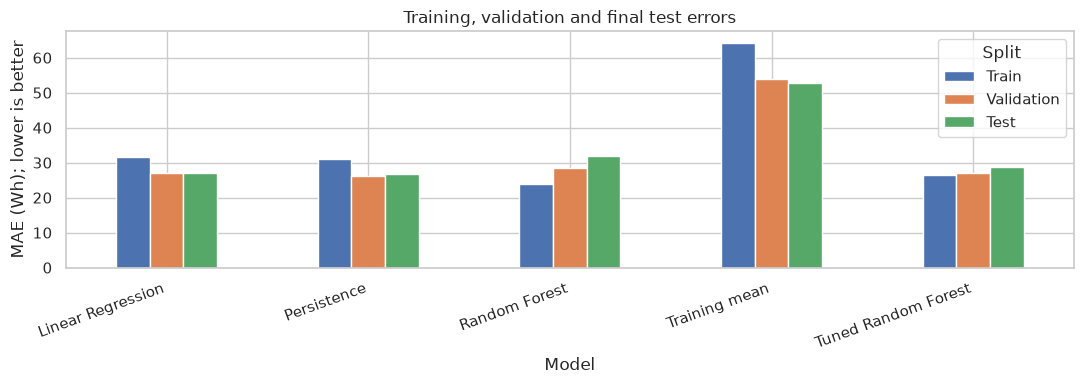

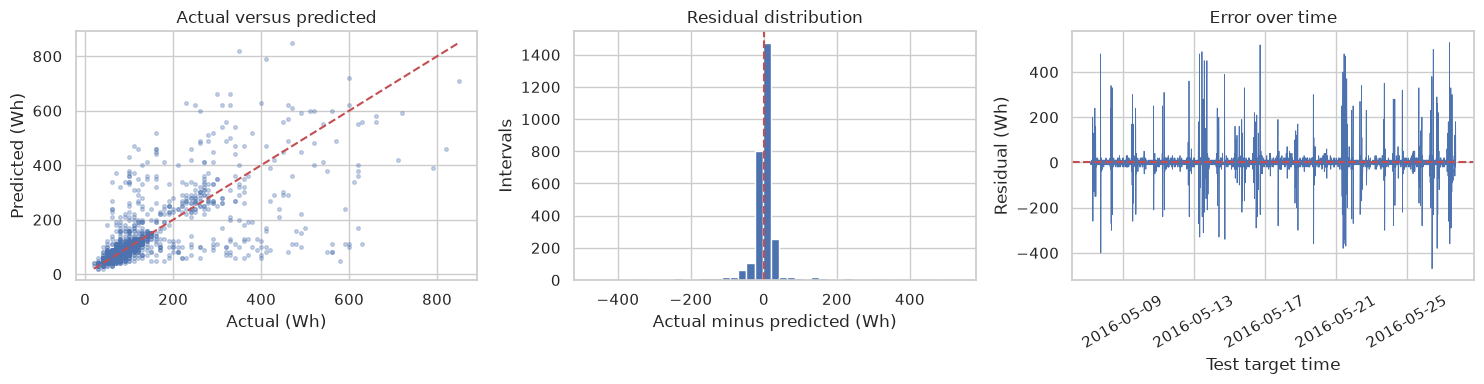

In [8]:
comparison = results.pivot(index='Model', columns='Split', values='MAE_Wh')
comparison[['Train', 'Validation', 'Test']].plot.bar(figsize=(11, 4))
plt.ylabel('MAE (Wh); lower is better')
plt.title('Training, validation and final test errors')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

pred = predict_with(best_name, X_test)
errors = pd.DataFrame({'Time': df.loc[X_test.index, 'target_time'].to_numpy(),
                       'Actual_Wh': y_test.to_numpy(), 'Predicted_Wh': pred})
errors['Residual_Wh'] = errors['Actual_Wh'] - errors['Predicted_Wh']
errors['Absolute_error_Wh'] = errors['Residual_Wh'].abs()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(errors.Actual_Wh, errors.Predicted_Wh, s=7, alpha=0.3)
limits = [min(errors.Actual_Wh.min(), errors.Predicted_Wh.min()), max(errors.Actual_Wh.max(), errors.Predicted_Wh.max())]
axes[0].plot(limits, limits, 'r--')
axes[0].set(xlabel='Actual (Wh)', ylabel='Predicted (Wh)', title='Actual versus predicted')
axes[1].hist(errors.Residual_Wh, bins=45)
axes[1].axvline(0, color='r', linestyle='--')
axes[1].set(xlabel='Actual minus predicted (Wh)', ylabel='Intervals', title='Residual distribution')
axes[2].plot(errors.Time, errors.Residual_Wh, linewidth=0.6)
axes[2].axhline(0, color='r', linestyle='--')
axes[2].set(xlabel='Test target time', ylabel='Residual (Wh)', title='Error over time')
axes[2].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

### Error analysis: peaks and unsuccessful predictions
Use the training 95th percentile as the high-consumption threshold. Large positive residuals mean underprediction. Compare errors for peaks and other intervals; a good overall MAE can conceal poor peak forecasts.

Peak threshold from training: 340.0 Wh


,Intervals,MAE_Wh,Mean_residual_Wh
Group,,,
High consumption,107,211.121,149.813
Other intervals,2853,19.832,-5.489


Five largest unsuccessful predictions:


,Time,Actual_Wh,Predicted_Wh,Residual_Wh,Absolute_error_Wh,Group
2909,2016-05-27 09:40:00,580.0,50,530.0,530.0,High consumption
1373,2016-05-16 17:40:00,630.0,110,520.0,520.0,High consumption
2777,2016-05-26 11:40:00,600.0,100,500.0,500.0,High consumption
902,2016-05-13 11:10:00,600.0,110,490.0,490.0,High consumption
80,2016-05-07 18:10:00,560.0,80,480.0,480.0,High consumption


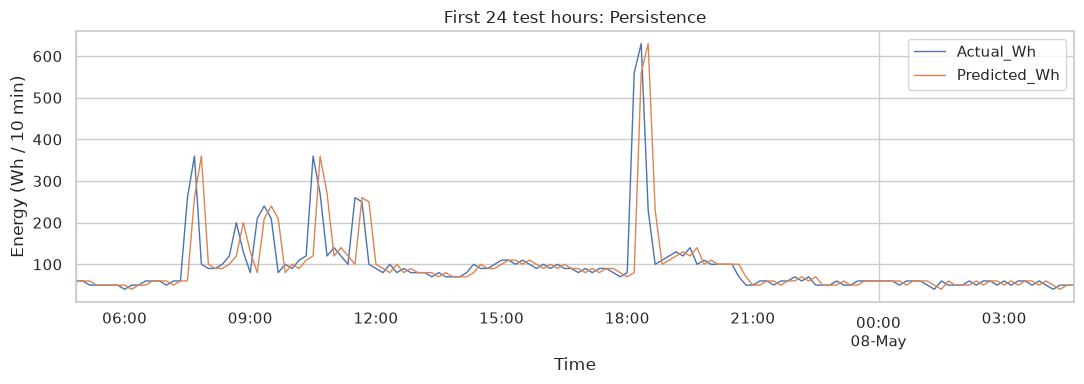

Negative predictions: 0 (unclipped; physically impossible values would need a deployment policy).


In [9]:
peak_threshold = y_train.quantile(0.95)
errors['Group'] = np.where(errors.Actual_Wh >= peak_threshold, 'High consumption', 'Other intervals')
print(f'Peak threshold from training: {peak_threshold:.1f} Wh')
display(errors.groupby('Group').agg(Intervals=('Absolute_error_Wh', 'size'),
                                    MAE_Wh=('Absolute_error_Wh', 'mean'),
                                    Mean_residual_Wh=('Residual_Wh', 'mean')).round(3))
print('Five largest unsuccessful predictions:')
display(errors.nlargest(5, 'Absolute_error_Wh'))
errors.head(144).plot(x='Time', y=['Actual_Wh', 'Predicted_Wh'], figsize=(11, 4), linewidth=1)
plt.ylabel('Energy (Wh / 10 min)')
plt.title(f'First 24 test hours: {best_name}')
plt.tight_layout()
plt.show()
print('Negative predictions:', int((pred < 0).sum()), '(unclipped; physically impossible values would need a deployment policy).')

### Which features help prediction?
Permutation importance shuffles one validation feature and measures the increase in MAE. We inspect the tuned forest because it can represent nonlinear relationships. This explains that candidate, even if it is not the selected model. Correlated inputs can share importance; this is predictive evidence, not causation. Validation importance is reported for interpretation and does not trigger another round of feature selection.

,Feature,Increase_in_MAE_Wh,Std_Wh
0,current_Wh,41.165,0.156
1,lag_10m_Wh,7.258,0.211
2,mean_1h_Wh,1.281,0.050
8,hour_sin,0.637,0.115
9,hour_cos,0.287,0.020
3,lights,0.050,0.012
10,is_weekend,-0.012,0.013
5,RH_1,-0.017,0.013
6,T_out,-0.068,0.032
4,T1,-0.202,0.029


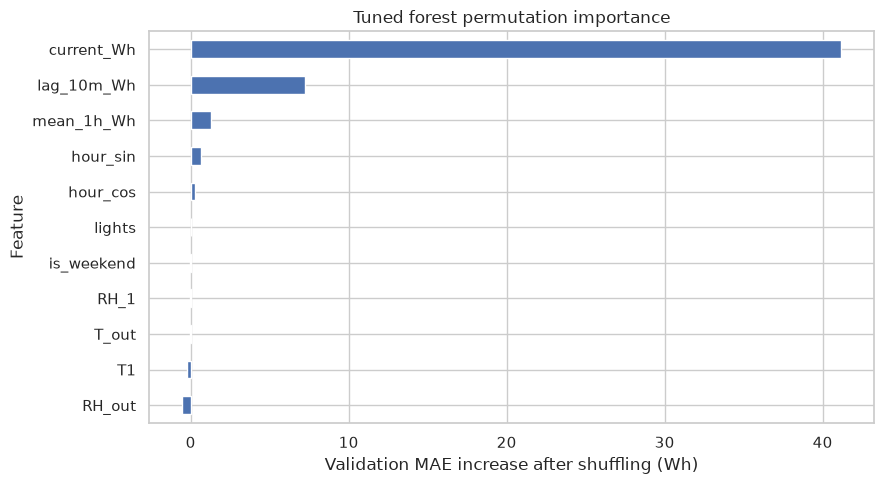

In [10]:
importance = permutation_importance(models['Tuned Random Forest'], X_val, y_val,
                                    scoring='neg_mean_absolute_error', n_repeats=3, random_state=SEED, n_jobs=1)
importance_table = pd.DataFrame({'Feature': feature_cols, 'Increase_in_MAE_Wh': importance.importances_mean,
                                 'Std_Wh': importance.importances_std}).sort_values('Increase_in_MAE_Wh', ascending=False)
display(importance_table.round(3))
importance_table.sort_values('Increase_in_MAE_Wh').plot.barh(x='Feature', y='Increase_in_MAE_Wh', legend=False, figsize=(9, 5))
plt.xlabel('Validation MAE increase after shuffling (Wh)')
plt.title('Tuned forest permutation importance')
plt.tight_layout()
plt.show()

## 12. A usable prediction example inside the notebook
This function takes **six consecutive, completed readings** and a tariff. It recreates the exact training features and predicts the next interval. The future target is not an input. In the example, we supply only history up to a test timestamp; the actual next reading is revealed separately afterward for comparison.

To demonstrate a different example, change `example_position`. A live system would replace this history with timestamped meter/sensor readings. This is a local demonstration; no API, web application or hosted deployment is claimed.

In [11]:
clean = pd.read_csv(DATA / 'clean_energydata.csv', parse_dates=['date'])

def predict_next_interval(history, tariff_per_kwh=8.0):
    required = ['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T_out', 'RH_out']
    history = history[required].tail(6).copy()
    if len(history) != 6 or not history['date'].diff().dropna().eq(pd.Timedelta(minutes=10)).all():
        raise ValueError('Provide six consecutive 10-minute readings, ordered oldest to newest.')
    if not np.isfinite(tariff_per_kwh) or tariff_per_kwh < 0:
        raise ValueError('Tariff must be a nonnegative finite number.')
    if not np.isfinite(history['Appliances']).all() or (history['Appliances'] < 0).any():
        raise ValueError('History must contain six valid nonnegative appliance readings.')
    latest = history.iloc[-1]
    target_time = latest['date'] + pd.Timedelta(minutes=10)
    hour = target_time.hour + target_time.minute / 60
    row = {'current_Wh': latest['Appliances'], 'lag_10m_Wh': history.iloc[-2]['Appliances'],
           'mean_1h_Wh': history['Appliances'].mean(),
           **{c: latest[c] for c in ['lights', 'T1', 'RH_1', 'T_out', 'RH_out']},
           'hour_sin': np.sin(2*np.pi*hour/24), 'hour_cos': np.cos(2*np.pi*hour/24),
           'is_weekend': int(target_time.day_of_week >= 5)}
    inputs = pd.DataFrame([row])[feature_cols]
    wh = float(predict_with(best_name, inputs)[0])
    return inputs, pd.Series({'Target time': target_time, 'Selected model': best_name,
                             'Predicted Wh': wh, 'Predicted kWh': wh / 1000,
                             'Estimated interval cost': wh / 1000 * tariff_per_kwh})

example_position = 24  # 0 to len(X_test)-1; choose a test interval.
tariff_per_kwh = 8.0  # Example assumption, in your chosen currency units per kWh.
example_index = X_test.index[example_position]
input_time = df.loc[example_index, 'date']
history = clean.loc[clean.date <= input_time].tail(6)
inputs, forecast = predict_next_interval(history, tariff_per_kwh)
assert np.allclose(inputs.to_numpy(dtype=float), X_test.loc[[example_index]].to_numpy(dtype=float), equal_nan=True)
print('Exact input row used:')
display(inputs)
display(forecast.to_frame('Value'))
print('Actual next reading (revealed after prediction):', y_test.loc[example_index], 'Wh')
print('Tariff is an example assumption; this is one interval cost, not a monthly bill.')

Exact input row used:


,current_Wh,lag_10m_Wh,mean_1h_Wh,lights,T1,RH_1,T_out,RH_out,hour_sin,hour_cos,is_weekend
0,200,120,116.666667,0,23.566667,39.2,16.466667,57.666667,0.737277,-0.67559,1


,Value
Target time,2016-05-07 08:50:00
Selected model,Persistence
Predicted Wh,200.0
Predicted kWh,0.2
Estimated interval cost,1.6


Actual next reading (revealed after prediction): 130.0 Wh
Tariff is an example assumption; this is one interval cost, not a monthly bill.


## Results and conclusion, calculated from this run
The next cell writes a short plain-language interpretation of the actual metrics. A higher test score does not retroactively change validation-based selection. A baseline winning is a valid result, not a reason to hide it.

**How to interpret the metric trade-off:** MAE and RMSE rank models differently. Persistence has the lowest validation MAE here, while the tuned forest has lower RMSE. Persistence is selected because MAE was the primary criterion chosen before training. This does not mean it is best at every type of error; the RMSE and peak-error results matter if preventing large misses is the operational goal.

In [12]:
selected_test = results[(results.Model == best_name) & (results.Split == 'Test')].iloc[0]
persistence_test = results[(results.Model == 'Persistence') & (results.Split == 'Test')].iloc[0]
print(f'Selected model: {best_name}.')
print(f'Final test MAE: {selected_test.MAE_Wh:.2f} Wh; RMSE: {selected_test.RMSE_Wh:.2f} Wh; R²: {selected_test.R2:.3f}.')
print(f'Test MAE difference versus persistence: {selected_test.MAE_Wh - persistence_test.MAE_Wh:+.2f} Wh (negative is better).')
if selected_test.MAE_Wh < persistence_test.MAE_Wh:
    print('The selected model improves average absolute error over persistence on this test period.')
elif best_name == 'Persistence':
    print('Persistence was selected: the more complex models did not beat it on validation MAE.')
else:
    print('The selected model does not beat persistence in test MAE on this period.')
peak_rows = errors[errors.Group == 'High consumption']
print(f'High-consumption test intervals: {len(peak_rows)}; MAE: {peak_rows.Absolute_error_Wh.mean():.2f} Wh.')
print('Prediction quality alone does not demonstrate energy savings.')

Selected model: Persistence.
Final test MAE: 26.75 Wh; RMSE: 66.85 Wh; R²: 0.459.
Test MAE difference versus persistence: +0.00 Wh (negative is better).
Persistence was selected: the more complex models did not beat it on validation MAE.
High-consumption test intervals: 107; MAE: 211.12 Wh.
Prediction quality alone does not demonstrate energy savings.


## Practical impact, limitations and future work
- **Users:** residents or an energy-management operator could use a short-term forecast to identify likely demand. Deferring a discretionary load is a possible action, not a demonstrated saving.
- **Data limits:** one Belgian house, roughly 4.5 months, limited seasonal coverage and unknown transferability to other buildings. Airport weather includes interpolated data, which limits claims about a truly live forecast.
- **Errors:** unseen appliance activity and sharp peaks can produce large misses. Historical features favor stable periods. Inspect the peak-error table and worst cases above before describing usefulness.
- **Model limits:** a small forest search and a compact feature set trade optimization for clarity. Correlations and importance do not identify causal energy-saving interventions.
- **Deployment adaptation:** the notebook function demonstrates new-input prediction locally. A real service additionally needs timely sensors, consistent units, monitoring, data-quality handling, retraining and integration with a scheduling system. No hosted deployment is claimed.
- **Future improvements:** collect multiple houses/seasons, obtain genuinely available weather inputs, test richer history only through time-aware validation, and measure savings in a real experiment.

## Viva: explain the project in one minute
“We forecast the next ten-minute appliance energy reading. First we validate the dataset, remove two artificial random columns and inspect patterns using only early data. We build eleven simple inputs from recent energy, a few sensors and time. We compare mean and persistence baselines against Linear Regression and Random Forest. We tune four forest settings with time-aware cross-validation. We choose by validation MAE and report an untouched chronological test period, including errors on peaks. Finally, a notebook function predicts from six completed readings. We do not claim that prediction itself saves energy.”

**Common questions:**
- Why no SMOTE? There are continuous values, not imbalanced classes.
- Why no random split? Neighbouring time observations are related; a future period is a more realistic test.
- Why scale only the linear model? Trees split by ordering; the linear pipeline uses comparable numerical scales.
- Why keep spikes? They may be genuine appliance activity; deleting them would hide difficult cases.
- Why two baseline models? Beating a constant is easy; beating the latest reading is more informative.
- Why does tuning not always help? CV and future periods differ, and limited searches do not guarantee improvement.
- Is the model causal? No. Predictive associations do not prove that changing a sensor value saves energy.

## PDF guideline checklist
| PDF requirement | Evidence in these notebooks |
|---|---|
| 1. Problem, users, input/output, constraints, impact | Notebook 1 §1; this notebook practical impact |
| 2. Source, collection, licence, size, types, limitations | Notebook 1 §2 and printed schema |
| 3. Preparation, formats, duplicates, counts | Notebook 1 §3 and original/clean sizes |
| 4. Missing data, outliers, categories, scaling, leakage | Notebook 1 §3–4; fitted pipelines and split assertions here |
| 5. Balancing and target distribution | Notebook 1 §4–5; peak analysis here |
| 6. Analytical EDA and resulting decisions | Notebook 1 §6, with interpretations and computed observations |
| 7. Feature engineering/selection and justification | Notebook 1 §7; history ablation and permutation importance here |
| 8. Baseline before advanced models | Mean and persistence evaluated before ML training |
| 9. At least two methods, assumptions and suitability | Linear Regression and Random Forest in §9 |
| 10. Hyperparameter tuning | Four settings × three expanding-window folds in §10 |
| 11. Appropriate validation/metrics; separate train/test; failures | Chronological splits, full metric table, residuals, peaks, worst examples |
| 12. Use, impact, risks, limitations, future work | Practical impact section and prediction function |
| Justify major decisions and validate AI code | Markdown before each stage; executed outputs, assertions, ablation and comparisons |
| Reproducibility and academic integrity | Fixed seed, explicit versions/dependencies, source list; actual executed results |
| Recommended architecture/application/deployment | Adapted to sequential notebooks and a local prediction function; no hosting claim |
| Deep learning configuration requirements | Not applicable: no neural network used; exclusion justified in §9 |

## Sources and AI-use record
- Dataset: Candanedo, L. (2017), UCI *Appliances Energy Prediction*, [doi:10.24432/C5VC8G](https://doi.org/10.24432/C5VC8G), CC BY 4.0. Sensor table supplied in the downloaded dataset zip.
- Assignment requirements: the provided *Guidelines_Machine_Learning_Innovative_Assignment.pdf*.
- Libraries: [pandas](https://pandas.pydata.org/docs/), [NumPy](https://numpy.org/doc/), [Matplotlib](https://matplotlib.org/stable/), [seaborn](https://seaborn.pydata.org/), [scikit-learn](https://scikit-learn.org/stable/), [Jupyter](https://jupyter.org/).
- AI assistance: Codex helped restructure and write these notebooks. Code was executed and outputs checked; students must still review, understand and explain it themselves. No results were copied from the previous app's metric files and no external project code was copied.